# Analyse of the elliptic dataset 

In [2]:
import pandas as pd

features = pd.read_csv("elliptic_txs_features.csv", header=None)
classes = pd.read_csv("elliptic_txs_classes.csv")
edgelist = pd.read_csv("elliptic_txs_edgelist.csv")

print(features.shape)
print(classes.shape)
print(edgelist.shape)

print(classes.columns.tolist())
print(classes.iloc[:, 1].value_counts())

(203769, 167)
(203769, 2)
(234355, 2)
['txId', 'class']
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64


From the print, we can see that the majority of data isn't usable to train an ML and that there is a big inequality between the licite and illicite data (42019 compared to 4545 licites)

In [3]:
# Renommer les colonnes utiles pour plus de clarté
features_ts = features[[0, 1]].rename(columns={0: 'txId', 1: 'time_step'})

# Fusionner avec les labels
merged = features_ts.merge(classes, on='txId')

# Garder seulement les transactions labellisées (exclure 'unknown')
labeled = merged[merged['class'] != 'unknown'].copy()

# Convertir la classe en 1 (illicite) ou 0 (licite) pour pouvoir calculer une moyenne
labeled['is_illicit'] = (labeled['class'] == '1').astype(int)

# Proportion d'illicite par time step
illicit_ratio_per_step = labeled.groupby('time_step')['is_illicit'].mean()*100

print(illicit_ratio_per_step.round(2))

time_step
1      0.79
2      1.61
3      0.86
4      2.08
5      0.43
6      1.03
7      8.48
8      5.75
9     31.88
10     1.85
11    18.82
12     3.16
13    35.97
14    10.31
15    23.79
16    24.15
17    12.21
18    13.37
19    10.74
20    28.89
21    15.60
22     8.96
23     4.47
24    12.17
25    19.87
26    18.57
27    11.65
28    29.93
29    28.02
30    15.84
31    14.93
32    25.85
33     5.22
34     7.18
35    13.57
36     1.93
37     8.03
38    14.68
39     6.85
40     9.25
41    10.25
42    11.10
43     1.75
44     1.51
45     0.41
46     0.28
47     2.60
48     7.64
49    11.76
Name: is_illicit, dtype: float64


we can see two important highs in the timesteps 9 and 13

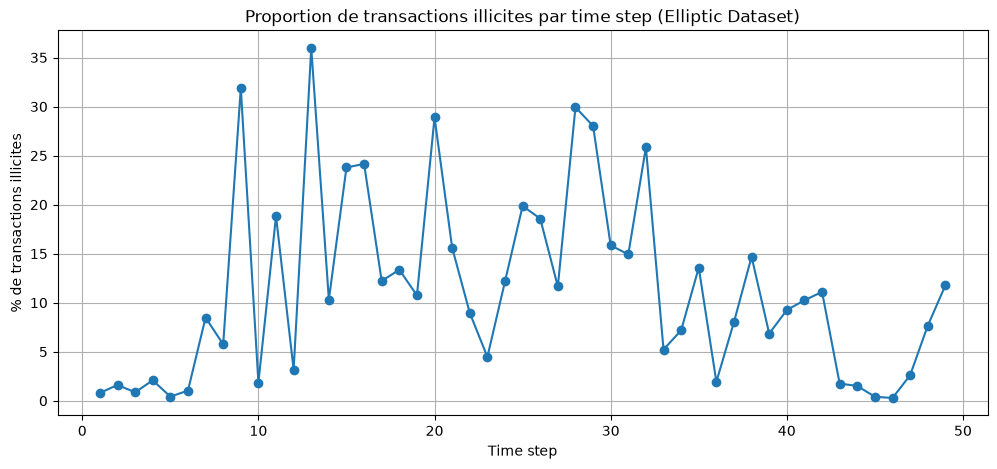

In [4]:
import matplotlib.pyplot as plt

illicit_ratio_per_step.plot(kind='line', marker='o', figsize=(12, 5))
plt.xlabel('Time step')
plt.ylabel('% de transactions illicites')
plt.title('Proportion de transactions illicites par time step (Elliptic Dataset)')
plt.grid(True)
plt.show()

In [5]:
# Fusionner toutes les features avec les labels (pas juste time_step cette fois)
full_merged = features.merge(classes, left_on=0, right_on='txId')

# Garder seulement les transactions labellisées
labeled_full = full_merged[full_merged['class'] != 'unknown'].copy()

# Comparer la moyenne de la feature colonne 2, entre illicite (1) et licite (2)
comparison = labeled_full.groupby('class')[2].mean()
print(comparison)

class
1   -0.165745
2   -0.040412
Name: 2, dtype: float64


In [6]:
# Calculer la moyenne de CHAQUE colonne, groupée par classe
means_by_class = labeled_full.groupby('class').mean(numeric_only=True)

# Calculer la différence absolue entre illicite (1) et licite (2) pour chaque colonne
diff = (means_by_class.loc['1'] - means_by_class.loc['2']).abs()

# Exclure les colonnes d'ID avant de comparer
diff_sorted_clean = diff.drop(index=[0, 'txId'], errors='ignore').sort_values(ascending=False)

print(diff_sorted_clean.head(10))

54    1.262973
56    1.082785
91    1.023468
90    1.000078
55    0.902200
53    0.853648
92    0.813541
60    0.753366
66    0.753319
61    0.707137
dtype: float64


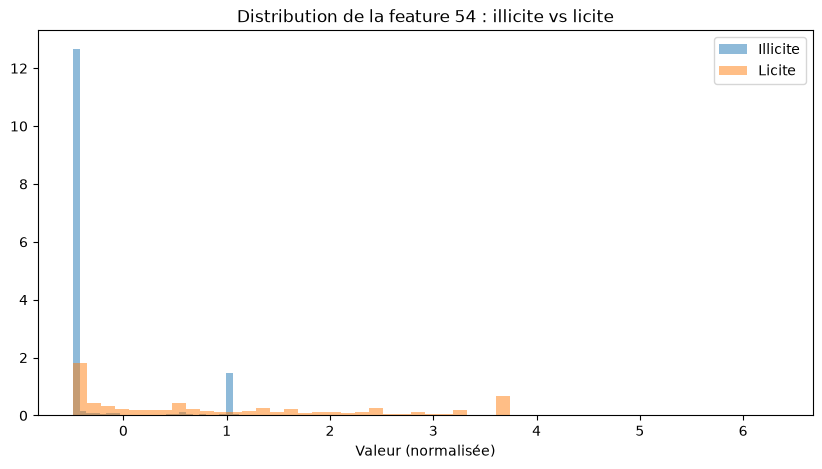

In [7]:
illicit_vals = labeled_full[labeled_full['class'] == '1'][54]
licit_vals = labeled_full[labeled_full['class'] == '2'][54]

plt.figure(figsize=(10, 5))
plt.hist(illicit_vals, bins=50, alpha=0.5, label='Illicite', density=True)
plt.hist(licit_vals, bins=50, alpha=0.5, label='Licite', density=True)
plt.legend()
plt.title('Distribution de la feature 54 : illicite vs licite')
plt.xlabel('Valeur (normalisée)')
plt.show()

Compared to BigQuery where we had to do th indexing ourselves (dust, structure inputs/outputs), here the dataset gives us the features pre-calculated which shows a measurable
and visual way to discriminate the different transactions - exactly why this dataset is used by many academic researches.

In [8]:
# Fusionner edgelist avec les classes, pour les deux côtés de chaque connexion
edges_with_class = edgelist.merge(classes, left_on='txId1', right_on='txId', suffixes=('', '_1'))
edges_with_class = edges_with_class.merge(classes, left_on='txId2', right_on='txId', suffixes=('_1', '_2'))

# Garder seulement les connexions où les deux transactions sont labellisées
edges_labeled = edges_with_class[
    (edges_with_class['class_1'] != 'unknown') &
    (edges_with_class['class_2'] != 'unknown')
]

# Compter les combinaisons de classes
print(edges_labeled.groupby(['class_1', 'class_2']).size())

class_1  class_2
1        1            998
         2            915
2        1            781
         2          33930
dtype: int64


In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Renommer proprement les colonnes utiles
features_all = features.rename(columns={0: 'txId', 1: 'time_step'})
data = features_all.merge(classes, on='txId')

# Garder seulement les transactions labellisées
data = data[data['class'] != 'unknown'].copy()
data['label'] = (data['class'] == '1').astype(int)  # 1 = illicite, 0 = licite

# Split temporel : time steps 1-34 = train, 35-49 = test
train = data[data['time_step'] <= 34]
test = data[data['time_step'] > 34]

# Les features sont toutes les colonnes numériques sauf txId, time_step, class, label
feature_cols = [c for c in features.columns if c not in [0, 1]]

X_train, y_train = train[feature_cols], train['label']
X_test, y_test = test[feature_cols], test['label']

print(X_train.shape, X_test.shape)

(29894, 165) (16670, 165)


In [10]:
# Entraînement
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# Prédiction sur le test (time steps 35-49, jamais vus par le modèle)
y_pred = rf.predict(X_test)

# Évaluation
print(classification_report(y_test, y_pred, target_names=['licite', 'illicite']))

              precision    recall  f1-score   support

      licite       0.98      1.00      0.99     15587
    illicite       0.97      0.72      0.83      1083

    accuracy                           0.98     16670
   macro avg       0.98      0.86      0.91     16670
weighted avg       0.98      0.98      0.98     16670



In [11]:
# Même modèle, mais avec pondération des classes
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_balanced.fit(X_train, y_train)

y_pred_bal = rf_balanced.predict(X_test)

print(classification_report(y_test, y_pred_bal, target_names=['licite', 'illicite']))

              precision    recall  f1-score   support

      licite       0.98      0.99      0.99     15587
    illicite       0.91      0.72      0.81      1083

    accuracy                           0.98     16670
   macro avg       0.94      0.86      0.90     16670
weighted avg       0.98      0.98      0.98     16670



In [12]:
test_eval = test.copy()
test_eval['pred'] = rf.predict(X_test)

recall_per_step = (
    test_eval[test_eval['label'] == 1]
    .groupby('time_step')
    .apply(lambda g: (g['pred'] == 1).mean())
)
print(recall_per_step.round(2))

time_step
35    0.97
36    0.97
37    0.65
38    0.90
39    0.93
40    0.63
41    0.93
42    0.79
43    0.00
44    0.04
45    0.00
46    0.50
47    0.00
48    0.00
49    0.02
dtype: float64


In [13]:
test_eval['is_pred_correct'] = (test_eval['pred'] == 1)
illicit_test = test_eval[test_eval['label'] == 1]

stats = illicit_test.groupby('time_step').agg(
    nb_illicit=('label', 'size'),
    nb_detected=('is_pred_correct', 'sum')
)
print(stats)

# Recall séparé avant / après le step 43
avant = illicit_test[illicit_test['time_step'] < 43]
apres = illicit_test[illicit_test['time_step'] >= 43]
print("Recall steps 35-42 :", round(avant['is_pred_correct'].mean(), 2))
print("Recall steps 43-49 :", round(apres['is_pred_correct'].mean(), 2))

           nb_illicit  nb_detected
time_step                         
35                182          176
36                 33           32
37                 40           26
38                111          100
39                 81           75
40                112           71
41                116          108
42                239          190
43                 24            0
44                 24            1
45                  5            0
46                  2            1
47                 22            0
48                 36            0
49                 56            1
Recall steps 35-42 : 0.85
Recall steps 43-49 : 0.02
